# ACDC — Full Dataset Preprocessing, Augmentation & Training




In [ ]:
# 1. Setup
from google.colab import drive
drive.mount('/content/drive')

!pip -q install monai nibabel

import os, glob, random, json, time
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import torch

# --- Paths: matches your existing project folder ---
ROOT = "/content/drive/MyDrive/Monai_ACDC-Project-work/ACDC"
TRAIN = ROOT + "/training"
TEST = ROOT + "/testing"

PROJECT_DIR = "/content/drive/MyDrive/Monai_ACDC-Project-work"
SPLITS_DIR = PROJECT_DIR + "/splits"
CHECKPOINT_DIR = PROJECT_DIR + "/checkpoints"
OUTPUT_DIR = PROJECT_DIR + "/outputs"
LOG_DIR = PROJECT_DIR + "/logs"

for d in [SPLITS_DIR, CHECKPOINT_DIR, OUTPUT_DIR, LOG_DIR]:
    os.makedirs(d, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cpu":
    print("WARNING: No GPU detected. Go to Runtime -> Change runtime type -> GPU "
          "before running the training section, or it will be extremely slow.")


Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 28.2 MB/s eta 0:00:00
Device: cuda


## Configuration
All key settings in one place (equivalent to `config.py`, kept inline here so nothing needs
to be imported from another file).

In [ ]:
# 2. Configuration
LABEL_MAP = {0: "background", 1: "RV", 2: "MYO", 3: "LV"}
NUM_CLASSES = len(LABEL_MAP)

TARGET_SPACING = (1.5, 1.5, 3.0)
ORIENTATION = "RAS"
INTENSITY_LOWER_PCT = 0.5
INTENSITY_UPPER_PCT = 99.5
PATCH_SIZE = (128, 128, 16)

VAL_FRACTION = 0.15
RANDOM_SEED = 42

BATCH_SIZE = 2
NUM_WORKERS = 2
CACHE_RATE = 1.0

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-5
MAX_EPOCHS = 15
VAL_INTERVAL = 2
USE_AMP = True

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
print("Config set.")


Config set.


## Step 1 — Build the full file list (every patient, not just patient001)

Scans every `patientXXX` folder in `training/`, finds both labeled frames (ED and ES) with
their ground-truth masks, and builds one `{"image":..., "label":...}` entry per frame —
exactly the format MONAI expects.

In [ ]:
# 3. Scan ALL patients and build image/label pairs
def find_frame_pairs(patient_dir):
    pairs = []
    frame_files = sorted(glob.glob(os.path.join(patient_dir, "*_frame??.nii.gz")))
    for img_path in frame_files:
        gt_path = img_path.replace(".nii.gz", "_gt.nii.gz")
        if os.path.exists(gt_path):
            pairs.append({"image": img_path, "label": gt_path})
    return pairs

def build_data_dicts(root_dir):
    patient_dirs = sorted(d for d in glob.glob(os.path.join(root_dir, "patient*")) if os.path.isdir(d))
    if not patient_dirs:
        raise RuntimeError(f"No 'patientXXX' folders found under {root_dir}. Check the ROOT path.")
    by_patient = {}
    for pdir in patient_dirs:
        pid = os.path.basename(pdir.rstrip("/"))
        pairs = find_frame_pairs(pdir)
        if pairs:
            by_patient[pid] = pairs
        else:
            print(f"[WARN] No frame/gt pairs found for {pid}, skipping.")
    return by_patient

by_patient = build_data_dicts(TRAIN)
total_frames = sum(len(v) for v in by_patient.values())
print(f"Patients found: {len(by_patient)}")
print(f"Total labeled frames (ED+ES): {total_frames}")


Patients found: 100
Total labeled frames (ED+ES): 200


## Step 2 — Train / Validation split (patient-level, 85/15)

Same logic as your demo notebook's Step 4, but now applied to build the actual file lists
used for training (not just an overlap check).

In [ ]:
# 4. Patient-level train/val split
patient_ids = sorted(by_patient.keys())
rng = random.Random(RANDOM_SEED)
rng.shuffle(patient_ids)

n_val = round(len(patient_ids) * VAL_FRACTION)
val_ids = patient_ids[:n_val]
train_ids = patient_ids[n_val:]

def flatten(ids):
    files = []
    for pid in ids:
        files.extend(by_patient[pid])
    return files

train_files = flatten(train_ids)
val_files = flatten(val_ids)

# Official ACDC testing/ folder usually has NO ground-truth masks (challenge test set).
# Detect this automatically: if it has masks, treat it as a labeled test set; if not,
# it's inference-only material (can't compute Dice/IoU against it).
test_patient_dirs = sorted(d for d in glob.glob(os.path.join(TEST, "patient*")) if os.path.isdir(d))
test_files = []
test_has_labels = False
for pdir in test_patient_dirs:
    pairs = find_frame_pairs(pdir)
    if pairs:
        test_files.extend(pairs)
        test_has_labels = True

print(f"Train patients: {len(train_ids)}  -> frames: {len(train_files)}")
print(f"Val patients  : {len(val_ids)}  -> frames: {len(val_files)}")
print(f"Test patients : {len(test_patient_dirs)}  -> labeled frames: {len(test_files)} "
      f"({'HAS ground truth, usable for metrics' if test_has_labels else 'NO ground truth, inference-only'})")

assert set(train_ids).isdisjoint(val_ids), "Train/val patient overlap detected!"

# Save splits so later notebooks/scripts can reuse them without re-scanning
with open(os.path.join(SPLITS_DIR, "train_files.json"), "w") as f:
    json.dump(train_files, f, indent=2)
with open(os.path.join(SPLITS_DIR, "val_files.json"), "w") as f:
    json.dump(val_files, f, indent=2)
with open(os.path.join(SPLITS_DIR, "test_files.json"), "w") as f:
    json.dump(test_files, f, indent=2)
print("Saved split files to", SPLITS_DIR)


Train patients: 85  -> frames: 170
Val patients  : 15  -> frames: 30
Test patients : 50  -> labeled frames: 100 (HAS ground truth, usable for metrics)
Saved split files to /content/drive/MyDrive/Monai_ACDC-Project-work/splits


## Step 3 — Preprocessing + augmentation pipelines (dictionary-based)

Same transforms as your demo, but using the **dictionary** versions (`...d`) so image and
mask are processed together, consistently, for every patient.

In [ ]:
# 5. Preprocessing + augmentation transform pipelines
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, EnsureTyped,
    Orientationd, Spacingd, CropForegroundd,
    ScaleIntensityRangePercentilesd, NormalizeIntensityd,
    SpatialPadd, RandCropByPosNegLabeld,
    RandFlipd, RandRotate90d, RandZoomd,
    RandGaussianNoised, RandAdjustContrastd, RandShiftIntensityd,
)

def base_preprocessing(keys=("image", "label")):
    return [
        LoadImaged(keys=list(keys)),
        EnsureChannelFirstd(keys=list(keys)),
        EnsureTyped(keys=list(keys)),
        Orientationd(keys=list(keys), axcodes=ORIENTATION),
        Spacingd(keys=list(keys), pixdim=TARGET_SPACING, mode=("bilinear", "nearest")),
        ScaleIntensityRangePercentilesd(
            keys=["image"], lower=INTENSITY_LOWER_PCT, upper=INTENSITY_UPPER_PCT,
            b_min=0.0, b_max=1.0, clip=True,
        ),
        NormalizeIntensityd(keys=["image"], nonzero=True, channel_wise=True),
        CropForegroundd(keys=list(keys), source_key="image", margin=15, allow_smaller=True),
    ]

def train_augmentations(keys=("image", "label")):
    return [
        SpatialPadd(keys=list(keys), spatial_size=PATCH_SIZE),
        RandCropByPosNegLabeld(
            keys=list(keys), label_key="label", spatial_size=PATCH_SIZE,
            pos=2, neg=1, num_samples=2, image_key="image", image_threshold=0,
        ),
        RandFlipd(keys=list(keys), prob=0.5, spatial_axis=0),
        RandFlipd(keys=list(keys), prob=0.5, spatial_axis=1),
        RandRotate90d(keys=list(keys), prob=0.5, max_k=3, spatial_axes=(0, 1)),
        RandZoomd(keys=list(keys), prob=0.2, min_zoom=0.9, max_zoom=1.1, mode=("trilinear", "nearest")),
        RandGaussianNoised(keys=["image"], prob=0.15, mean=0.0, std=0.03),
        RandAdjustContrastd(keys=["image"], prob=0.2, gamma=(0.7, 1.5)),
        RandShiftIntensityd(keys=["image"], prob=0.3, offsets=0.1),
    ]

def get_train_transforms():
    return Compose(base_preprocessing() + train_augmentations() + [EnsureTyped(keys=("image", "label"))])

def get_val_transforms():
    return Compose(base_preprocessing() + [
        SpatialPadd(keys=("image", "label"), spatial_size=PATCH_SIZE),
        EnsureTyped(keys=("image", "label")),
    ])

train_transforms = get_train_transforms()
val_transforms = get_val_transforms()
print("Transform pipelines built.")


Transform pipelines built.


/usr/local/lib/python3.13/dist-packages/monai/utils/deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


## Step 4 — Apply the pipeline to the WHOLE dataset (verification pass)



In [ ]:
# 6. Run preprocessing on every file in train+val and log the results
import csv

all_files = [("train", f) for f in train_files] + [("val", f) for f in val_files]
report_rows = []
failures = []

print(f"Verifying preprocessing on {len(all_files)} frames... this may take a few minutes.")
t0 = time.time()

for i, (split_name, entry) in enumerate(all_files):
    try:
        sample = val_transforms(entry)  # deterministic pipeline only (no random augmentation)
        img_shape = tuple(sample["image"].shape)
        lbl_shape = tuple(sample["label"].shape)
        report_rows.append({
            "split": split_name,
            "image": os.path.basename(entry["image"]),
            "status": "OK",
            "image_shape": img_shape,
            "label_shape": lbl_shape,
        })
    except Exception as e:
        failures.append((entry["image"], str(e)))
        report_rows.append({
            "split": split_name,
            "image": os.path.basename(entry["image"]),
            "status": f"FAILED: {e}",
            "image_shape": None,
            "label_shape": None,
        })
    if (i + 1) % 20 == 0 or (i + 1) == len(all_files):
        print(f"  processed {i+1}/{len(all_files)}")

elapsed = time.time() - t0
print(f"\nDone in {elapsed:.1f}s. Success: {len(all_files) - len(failures)}/{len(all_files)}. Failures: {len(failures)}")

if failures:
    print("\nFAILED FILES:")
    for path, err in failures:
        print(" -", path, "->", err)

report_path = os.path.join(OUTPUT_DIR, "preprocessing_report.csv")
with open(report_path, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["split", "image", "status", "image_shape", "label_shape"])
    writer.writeheader()
    writer.writerows(report_rows)
print("Saved report to", report_path)


Verifying preprocessing on 200 frames... this may take a few minutes.
  processed 20/200
  processed 40/200
  processed 60/200
  processed 80/200
  processed 100/200
  processed 120/200
  processed 140/200
  processed 160/200
  processed 180/200
  processed 200/200

Done in 251.6s. Success: 200/200. Failures: 0
Saved report to /content/drive/MyDrive/Monai_ACDC-Project-work/outputs/preprocessing_report.csv


## Step 5 — Wire into MONAI DataLoaders

This is what actually "applies" preprocessing + augmentation during training: every time a
batch is requested, this pipeline runs automatically on the fly.

In [ ]:
# 9. Build CacheDataset + DataLoader
from monai.data import CacheDataset, DataLoader, list_data_collate

train_ds = CacheDataset(data=train_files, transform=train_transforms,
                         cache_rate=CACHE_RATE, num_workers=NUM_WORKERS)
val_ds = CacheDataset(data=val_files, transform=val_transforms,
                       cache_rate=CACHE_RATE, num_workers=NUM_WORKERS)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                           num_workers=NUM_WORKERS, collate_fn=list_data_collate,
                           pin_memory=True, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=1, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

batch = next(iter(train_loader))
print("Train batch image shape:", batch["image"].shape)
print("Train batch label shape:", batch["label"].shape)


Loading dataset: 100%|██████████| 30/30 [00:11<00:00,  2.70it/s]


Train batch image shape: torch.Size([4, 1, 128, 128, 16])
Train batch label shape: torch.Size([4, 1, 128, 128, 16])


## Step 6 — Model: 3D U-Net


In [ ]:
# 10. Build the 3D U-Net
from monai.networks.nets import UNet
from monai.networks.layers import Norm

model = UNet(
    spatial_dims=3,
    in_channels=1,
    out_channels=NUM_CLASSES,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    num_res_units=2,
    norm=Norm.BATCH,
    dropout=0.1,
).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters())
print(f"Model built: 3D U-Net ({n_params:,} parameters)")


Model built: 3D U-Net (4,810,977 parameters)


## Step 7 — Training implementation

Loss (Dice + Cross-Entropy), optimizer (AdamW), learning-rate scheduler, mixed precision
(AMP), and the Dice metric for validation — all from MONAI, matching your abstract's
"optimization techniques and inference strategies available in the MONAI framework".

In [ ]:
# 11. Loss, optimizer, scheduler, metric
from monai.losses import DiceCELoss
from monai.metrics import DiceMetric
from monai.transforms import AsDiscrete
from monai.inferers import sliding_window_inference

loss_function = DiceCELoss(to_onehot_y=True, softmax=True)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_EPOCHS)

dice_metric = DiceMetric(include_background=False, reduction="mean")
post_pred = AsDiscrete(argmax=True, to_onehot=NUM_CLASSES)
post_label = AsDiscrete(to_onehot=NUM_CLASSES)

AMP_DEVICE = DEVICE.type  # "cuda" or "cpu" - keeps autocast/GradScaler device-aware
scaler = torch.amp.GradScaler(AMP_DEVICE, enabled=(USE_AMP and DEVICE.type == "cuda"))
print("Loss, optimizer, scheduler, and metric ready.")


Loss, optimizer, scheduler, and metric ready.


In [ ]:
# 12. Training loop
def validate(model, loader):
    model.eval()
    dice_metric.reset()
    with torch.no_grad():
        for batch in loader:
            images = batch["image"].to(DEVICE)
            labels = batch["label"].to(DEVICE)
            with torch.amp.autocast(AMP_DEVICE, enabled=(USE_AMP and DEVICE.type == "cuda")):
                outputs = sliding_window_inference(
                    images, roi_size=PATCH_SIZE, sw_batch_size=1, predictor=model, overlap=0.5
                )
            outputs_list = [post_pred(x) for x in torch.unbind(outputs, dim=0)]
            labels_list = [post_label(x) for x in torch.unbind(labels, dim=0)]
            dice_metric(y_pred=outputs_list, y=labels_list)
    mean_dice = dice_metric.aggregate().item()
    dice_metric.reset()
    return mean_dice


def train(model, train_loader, val_loader, max_epochs):
    best_metric = -1
    best_epoch = -1
    history = {"train_loss": [], "val_dice": [], "val_epoch": []}

    for epoch in range(1, max_epochs + 1):
        model.train()
        epoch_loss = 0.0
        step = 0
        t0 = time.time()

        for batch in train_loader:
            step += 1
            images = batch["image"].to(DEVICE)
            labels = batch["label"].to(DEVICE)

            optimizer.zero_grad()
            with torch.amp.autocast(AMP_DEVICE, enabled=(USE_AMP and DEVICE.type == "cuda")):
                outputs = model(images)
                loss = loss_function(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            epoch_loss += loss.item()

        epoch_loss /= max(step, 1)
        lr_scheduler.step()

        history["train_loss"].append(epoch_loss)
        print(f"Epoch {epoch}/{max_epochs} - loss: {epoch_loss:.4f} - time: {time.time()-t0:.1f}s")

        if epoch % VAL_INTERVAL == 0:
            mean_dice = validate(model, val_loader)
            history["val_dice"].append(mean_dice)
            history["val_epoch"].append(epoch)
            print(f"  Validation mean Dice: {mean_dice:.4f}")

            if mean_dice > best_metric:
                best_metric = mean_dice
                best_epoch = epoch
                ckpt_path = os.path.join(CHECKPOINT_DIR, "best_model.pt")
                torch.save({
                    "epoch": epoch,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "best_metric": best_metric,
                }, ckpt_path)
                print(f"  New best model saved (Dice={best_metric:.4f}) -> {ckpt_path}")

    print(f"\nTraining complete. Best Dice: {best_metric:.4f} at epoch {best_epoch}")
    return history

print("Training function defined. Run the next cell to start training.")


Training function defined. Run the next cell to start training.


In [ ]:
# 13. Run it
history = train(model, train_loader, val_loader, max_epochs=MAX_EPOCHS)


Epoch 1/15 - loss: 1.9990 - time: 15.1s
Epoch 2/15 - loss: 1.5906 - time: 13.7s
  Validation mean Dice: 0.1264
  New best model saved (Dice=0.1264) -> /content/drive/MyDrive/Monai_ACDC-Project-work/checkpoints/best_model.pt
Epoch 3/15 - loss: 1.3154 - time: 13.9s
Epoch 4/15 - loss: 1.1038 - time: 13.5s
  Validation mean Dice: 0.2697
  New best model saved (Dice=0.2697) -> /content/drive/MyDrive/Monai_ACDC-Project-work/checkpoints/best_model.pt
Epoch 5/15 - loss: 1.0056 - time: 14.1s
Epoch 6/15 - loss: 0.9249 - time: 13.5s
  Validation mean Dice: 0.3501
  New best model saved (Dice=0.3501) -> /content/drive/MyDrive/Monai_ACDC-Project-work/checkpoints/best_model.pt
Epoch 7/15 - loss: 0.8648 - time: 13.5s
Epoch 8/15 - loss: 0.8247 - time: 13.6s
  Validation mean Dice: 0.5343
  New best model saved (Dice=0.5343) -> /content/drive/MyDrive/Monai_ACDC-Project-work/checkpoints/best_model.pt
Epoch 9/15 - loss: 0.7865 - time: 13.7s
Epoch 10/15 - loss: 0.7544 - time: 13.3s
  Validation mean Dice:

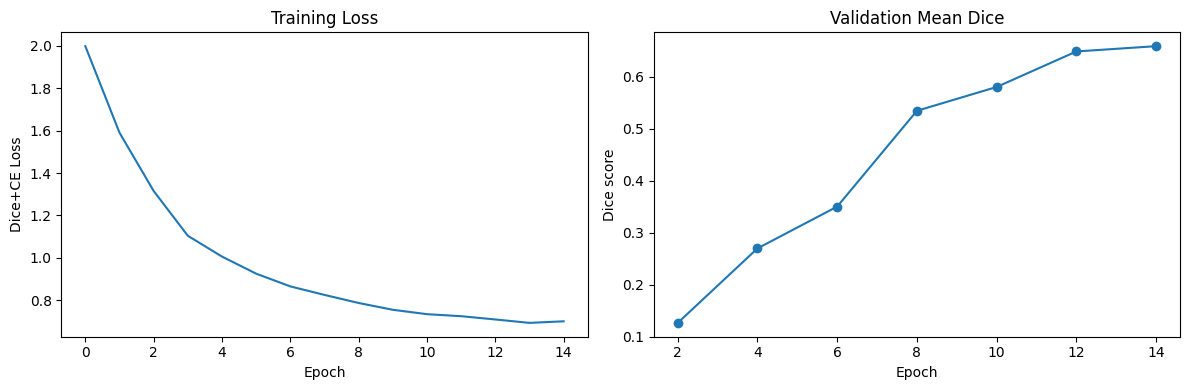

Saved: /content/drive/MyDrive/Monai_ACDC-Project-work/outputs/training_curves.png


In [ ]:
# 14. Plot training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["train_loss"])
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Dice+CE Loss")

axes[1].plot(history["val_epoch"], history["val_dice"], marker="o")
axes[1].set_title("Validation Mean Dice")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Dice score")

plt.tight_layout()
save_path = os.path.join(OUTPUT_DIR, "training_curves.png")
plt.savefig(save_path, dpi=150)
plt.show()
print("Saved:", save_path)


---
### Next steps

1. **`evaluate.py`** — load `checkpoints/best_model.pt` and compute Dice, IoU, HD95, precision,
   recall on the validation set (and the internal or official test set)
2. **`inference.py`** — run sliding-window inference on brand-new, unseen scans
3. **`visualize_results.py`** — ground-truth vs predicted overlay images for the report
4. **`app.py`** — Streamlit demo: upload a scan, see the segmentation
5. Final README + report for GitHub submission
